In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = pd.read_csv("/sales_data.csv")

data.head()

,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep
0,1052,2023-02-03,Bob,North,5053.97,18,Furniture,152.75,267.22,Returning,0.09,Cash,Online,North-Bob
1,1093,2023-04-21,Bob,West,4384.02,17,Furniture,3816.39,4209.44,Returning,0.11,Cash,Retail,West-Bob
2,1015,2023-09-21,David,South,4631.23,30,Food,261.56,371.40,Returning,0.20,Bank Transfer,Retail,South-David
3,1072,2023-08-24,Bob,South,2167.94,39,Clothing,4330.03,4467.75,New,0.02,Credit Card,Retail,South-Bob
4,1061,2023-03-24,Charlie,East,3750.20,13,Electronics,637.37,692.71,New,0.08,Credit Card,Online,East-Charlie


In [4]:
data.info()
data.shape
data.isnull().sum()
data.duplicated().sum()
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Product_ID            1000 non-null   int64  
 1   Sale_Date             1000 non-null   object 
 2   Sales_Rep             1000 non-null   object 
 3   Region                1000 non-null   object 
 4   Sales_Amount          1000 non-null   float64
 5   Quantity_Sold         1000 non-null   int64  
 6   Product_Category      1000 non-null   object 
 7   Unit_Cost             1000 non-null   float64
 8   Unit_Price            1000 non-null   float64
 9   Customer_Type         1000 non-null   object 
 10  Discount              1000 non-null   float64
 11  Payment_Method        1000 non-null   object 
 12  Sales_Channel         1000 non-null   object 
 13  Region_and_Sales_Rep  1000 non-null   object 
dtypes: float64(4), int64(2), object(8)
memory usage: 109.5+ KB


,Product_ID,Sales_Amount,Quantity_Sold,Unit_Cost,Unit_Price,Discount
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,1050.128000,5019.265230,25.355000,2475.304550,2728.440120,0.15239
std,29.573505,2846.790126,14.159006,1417.872546,1419.399839,0.08720
min,1001.000000,100.120000,1.000000,60.280000,167.120000,0.00000
25%,1024.000000,2550.297500,13.000000,1238.380000,1509.085000,0.08000
50%,1051.000000,5019.300000,25.000000,2467.235000,2696.400000,0.15000
75%,1075.000000,7507.445000,38.000000,3702.865000,3957.970000,0.23000
max,1100.000000,9989.040000,49.000000,4995.300000,5442.150000,0.30000


In [5]:
for col in data.select_dtypes(include="object").columns:
    data[col] = data[col].str.strip()
data["Sale_Date"] = pd.to_datetime(data["Sale_Date"], errors="coerce")
data = data.drop_duplicates()
print("Missing Values:")
print(data.isnull().sum())

print("Duplicate Rows:", data.duplicated().sum())

print("Date Data Type:", data["Sale_Date"].dtype)

print("Dataset Shape:", data.shape)

Missing Values:
Product_ID              0
Sale_Date               0
Sales_Rep               0
Region                  0
Sales_Amount            0
Quantity_Sold           0
Product_Category        0
Unit_Cost               0
Unit_Price              0
Customer_Type           0
Discount                0
Payment_Method          0
Sales_Channel           0
Region_and_Sales_Rep    0
dtype: int64
Duplicate Rows: 0
Date Data Type: datetime64[ns]
Dataset Shape: (1000, 14)


In [6]:
total_sales = data["Sales_Amount"].sum()
print("Total Sales:", total_sales)
average_sales = data["Sales_Amount"].mean()
print("Average Sales:", average_sales)
total_quantity = data["Quantity_Sold"].sum()
print("Total Quantity Sold:", total_quantity)
category_sales = data.groupby("Product_Category")["Sales_Amount"].sum()
print("\nSales by Product Category:")
print(category_sales)
region_sales = data.groupby("Region")["Sales_Amount"].sum()
print("\nSales by Region:")
print(region_sales)

Total Sales: 5019265.2299999995
Average Sales: 5019.265229999999
Total Quantity Sold: 25355

Sales by Product Category:
Product_Category
Clothing       1313474.36
Electronics    1243499.64
Food           1201773.54
Furniture      1260517.69
Name: Sales_Amount, dtype: float64

Sales by Region:
Region
East     1259792.93
North    1369612.51
South    1154250.86
West     1235608.93
Name: Sales_Amount, dtype: float64


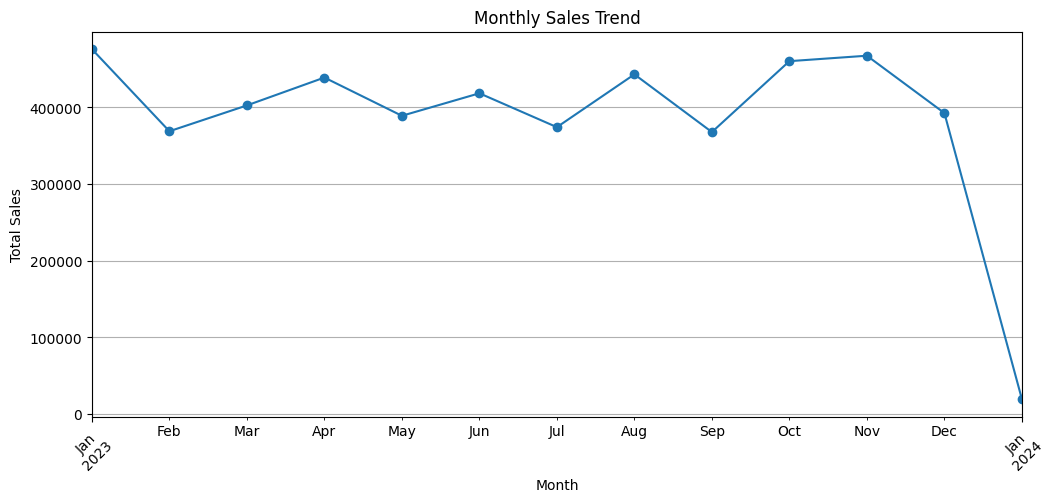

In [7]:
data["Month"] = data["Sale_Date"].dt.to_period("M")

monthly_sales = data.groupby("Month")["Sales_Amount"].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

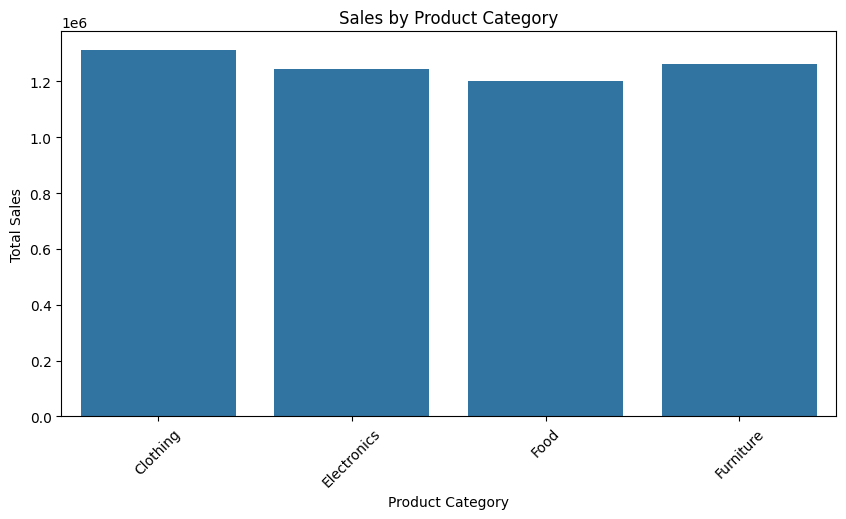

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

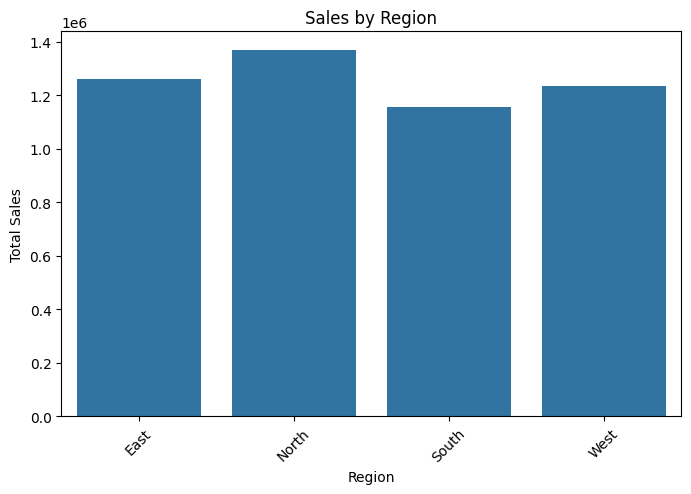

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [10]:
Q1 = data["Sales_Amount"].quantile(0.25)
Q3 = data["Sales_Amount"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 2550.2975
Q3: 7507.445000000001
IQR: 4957.147500000001
Lower Bound: -4885.423750000002
Upper Bound: 14943.166250000002


In [11]:
outliers = data[
    (data["Sales_Amount"] < lower_bound) |
    (data["Sales_Amount"] > upper_bound)
]

print("Number of Outliers:", len(outliers))
outliers

Number of Outliers: 0


,Product_ID,Sale_Date,Sales_Rep,Region,Sales_Amount,Quantity_Sold,Product_Category,Unit_Cost,Unit_Price,Customer_Type,Discount,Payment_Method,Sales_Channel,Region_and_Sales_Rep,Month


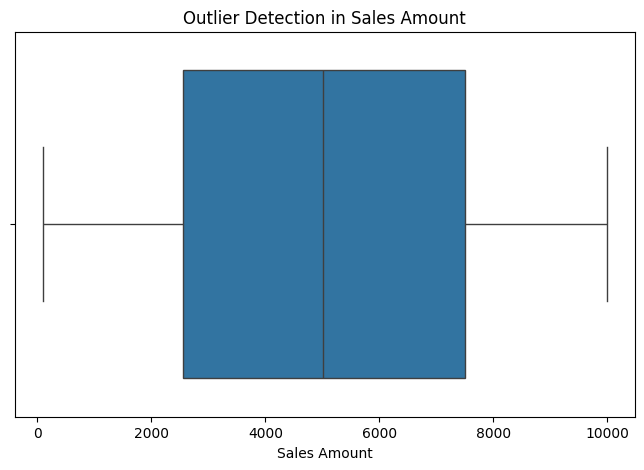

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=data["Sales_Amount"])

plt.title("Outlier Detection in Sales Amount")
plt.xlabel("Sales Amount")

plt.show()

In [13]:
print("Final Dataset Shape:", data.shape)

print("Missing Values:", data.isnull().sum().sum())

print("Duplicate Rows:", data.duplicated().sum())

Final Dataset Shape: (1000, 15)
Missing Values: 0
Duplicate Rows: 0


In [14]:
data.to_csv("Retail_Sales_Cleaned.csv", index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [15]:
from google.colab import files

files.download("Retail_Sales_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>